In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [26]:
# 1. Carregar os dados
df = pd.read_csv('../../data/processed/dispensacao_analitico.csv', parse_dates=['data'])
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 220815 entries, 0 to 220814
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   competencia_inicial              220815 non-null  int64         
 1   competencia_final                219080 non-null  float64       
 2   ups_nome                         220815 non-null  str           
 3   ups_codigo                       220815 non-null  int64         
 4   bairro_nome                      220815 non-null  str           
 5   bairro_codigo                    220792 non-null  float64       
 6   centro_custo_nome                220815 non-null  str           
 7   centro_custo_codigo              21543 non-null   float64       
 8   material_nome                    220815 non-null  str           
 9   material_nome_base               220815 non-null  str           
 10  material_descricao_complementar  220815 non-null  str  

,competencia_inicial,competencia_final,ups_nome,ups_codigo,bairro_nome,bairro_codigo,centro_custo_nome,centro_custo_codigo,material_nome,material_nome_base,...,data,saida,usuario,fabricante_codigo,fabricante_nome,lote,numero_receita,validade,quantidade,custo_medio
0,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,CARBONATO DE LITIO - 300MG - COMPRIMIDO,CARBONATO DE LITIO,...,2025-09-02,776110,X,41.0,CRISTALIA,23100497,NaN,2025-10-02,90,0.19
1,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,CLORPROMAZINA - 25MG - COMPRIMIDO,CLORPROMAZINA,...,2025-09-18,781751,X,41.0,CRISTALIA,50023423,NaN,2027-01-30,240,0.28
2,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,IMIPRAMINA - 25MG - COMPRIMIDO,IMIPRAMINA,...,2025-09-09,778225,X,41.0,CRISTALIA,50025335,NaN,2027-01-31,180,0.44
3,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,MIRTAZAPINA - 45MG - COMPRIMIDO,MIRTAZAPINA,...,2025-09-18,781751,X,2.0,PRATI DONADUZZI,25D360,NaN,2027-03-13,60,0.86
4,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,VENLAFAXINA - 75MG - COMPRIMIDO,VENLAFAXINA,...,2025-09-02,776110,X,40.0,AUROBINDO,VWB25001,NaN,2027-12-31,120,0.36


In [27]:
def plotar_variacao_mensal(df, ax, coluna):
  df['ano_mes'] = df['data'].dt.to_period('M')
  mensal = df.groupby('ano_mes')['quantidade'].sum().reset_index()
  mensal['ano_mes_str'] = mensal['ano_mes'].astype(str)

  # 3. Remover o último mês se estiver incompleto (poucos dias de dados)
  dias_por_mes = df.groupby('ano_mes')['data'].nunique()
  if dias_por_mes.iloc[-1] < 15:  # menos de metade do mês
      mensal = mensal.iloc[:-1]

  # 4. Calcular variação percentual mês a mês
  mensal['variacao_pct'] = mensal['quantidade'].pct_change() * 100

  # 5. Definir o que é "variação relevante" (acima de 8% de mudança)
  LIMIAR = 8
  mensal['relevante'] = mensal['variacao_pct'].abs() >= LIMIAR

  # 6. Plotar
  cores = ['#d62728' if (rel and var < 0) else '#2ca02c' if (rel and var > 0) else '#1f77b4'
          for rel, var in zip(mensal['relevante'], mensal['variacao_pct'].fillna(0))]

  ax.plot(mensal['ano_mes_str'], mensal['quantidade'], marker='o', linewidth=2, zorder=1,label = coluna)
  ax.scatter(mensal['ano_mes_str'], mensal['quantidade'], c=cores, s=90, zorder=2, edgecolor='white')

  # Anotar variação percentual relevante
  for i, row in mensal.iterrows():
      if row['relevante']:
          ax.annotate(f"{row['variacao_pct']:+.1f}%",
                      (row['ano_mes_str'], row['quantidade']),
                      textcoords="offset points", xytext=(0, 12),
                      ha='center', fontsize=9, fontweight='bold',
                      color='#d62728' if row['variacao_pct'] < 0 else '#2ca02c')


  # 7. Listar períodos com variação relevante
  print("\nPeríodos com variação relevante (>= {}%):".format(LIMIAR))
  print(mensal[mensal['relevante']][['ano_mes_str', 'quantidade', 'variacao_pct']].to_string(index=False))

In [28]:
def variacao_mensal_coluna(df, coluna):
  df_ordenado = df.sort_values(by=[coluna, "quantidade"], ascending=[True, False])

  fig, ax = plt.subplots(figsize=(12, 6))

  aux = 0
  for nome, grupo_df in df_ordenado.groupby(coluna):
    if aux > 4:
      break
    aux += 1
    plotar_variacao_mensal(grupo_df, ax, nome)

  ax.set_title('Quantidade total dispensada por mês', fontsize=14, fontweight='bold')
  ax.set_xlabel('Mês')
  ax.set_ylabel('Quantidade dispensada')
  plt.xticks(rotation=45)
  ax.grid(axis='y', alpha=0.3)
  ax.legend(loc='best')

  plt.tight_layout()
  plt.savefig('grafico_dispensacao_mensal.png', dpi=150)
  plt.show()


Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-11      759042    -14.806754
    2025-12      828313      9.126109
    2026-03      861769     11.774052
    2026-05      794354     -9.963832


C:\Users\mirel\AppData\Local\Temp\ipykernel_7240\3776057042.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


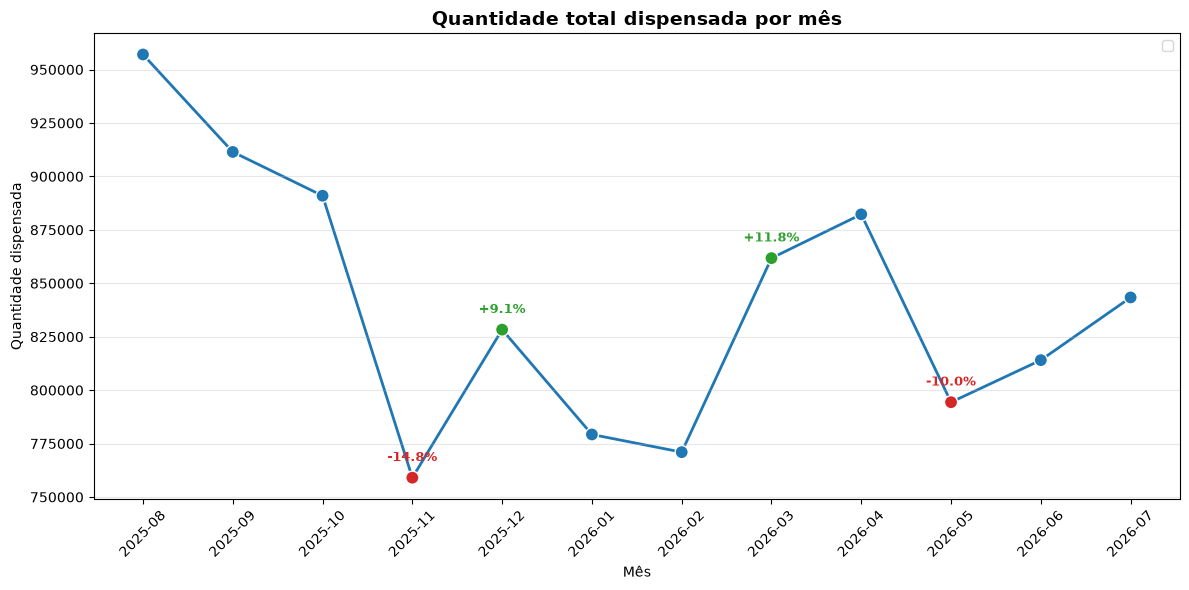

In [29]:
fig, ax = plt.subplots(figsize=(12, 6))

plotar_variacao_mensal(df, ax, '')

ax.set_title('Quantidade total dispensada por mês', fontsize=14, fontweight='bold')
ax.set_xlabel('Mês')
ax.set_ylabel('Quantidade dispensada')
plt.xticks(rotation=45)
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='best')

plt.tight_layout()
plt.savefig('grafico_dispensacao_mensal.png', dpi=150)
plt.show()

### Como diferentes medicamentos, bairros ou centros de custo se comportam no tempo?

In [30]:
print("Quantidade de Medicamentos Cadastrados........: ", df.groupby("material_nome").ngroups)
print("Quantidade de Bairros Cadastrados.............: ", df.groupby("bairro_nome").ngroups)
print("Quantidade de UPS Cadastrados.................: ", df.groupby("ups_nome").ngroups)
print("Quantidade de Centros Custo Cadastrados.......: ", df.groupby("centro_custo_nome").ngroups)
print("Quantidade de Tipos Cadastrados...............: ", df.groupby("material_tipo").ngroups)
print("Quantidade de Classes Terapêuticas Cadastrados: ", df.groupby("classe_terapeutica").ngroups)

Quantidade de Medicamentos Cadastrados........:  167
Quantidade de Bairros Cadastrados.............:  215
Quantidade de UPS Cadastrados.................:  1
Quantidade de Centros Custo Cadastrados.......:  13
Quantidade de Tipos Cadastrados...............:  8
Quantidade de Classes Terapêuticas Cadastrados:  56



Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-09         310     27.049180
    2025-10         359     15.806452
    2025-11         464     29.247911
    2026-02         305    -33.839479
    2026-04         550     74.050633
    2026-05         234    -57.454545
    2026-06         294     25.641026
    2026-07         424     44.217687

Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-10          95    -30.656934
    2025-12         185     88.775510
    2026-01          96    -48.108108
    2026-02         134     39.583333
    2026-03         150     11.940299
    2026-04          91    -39.333333
    2026-05         149     63.736264
    2026-06         100    -32.885906

Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-11       55756    -17.350766
    2026-02       53724    -11.799182
    2026-03       64560     20.169757
    2026-05       54438    -12.321221


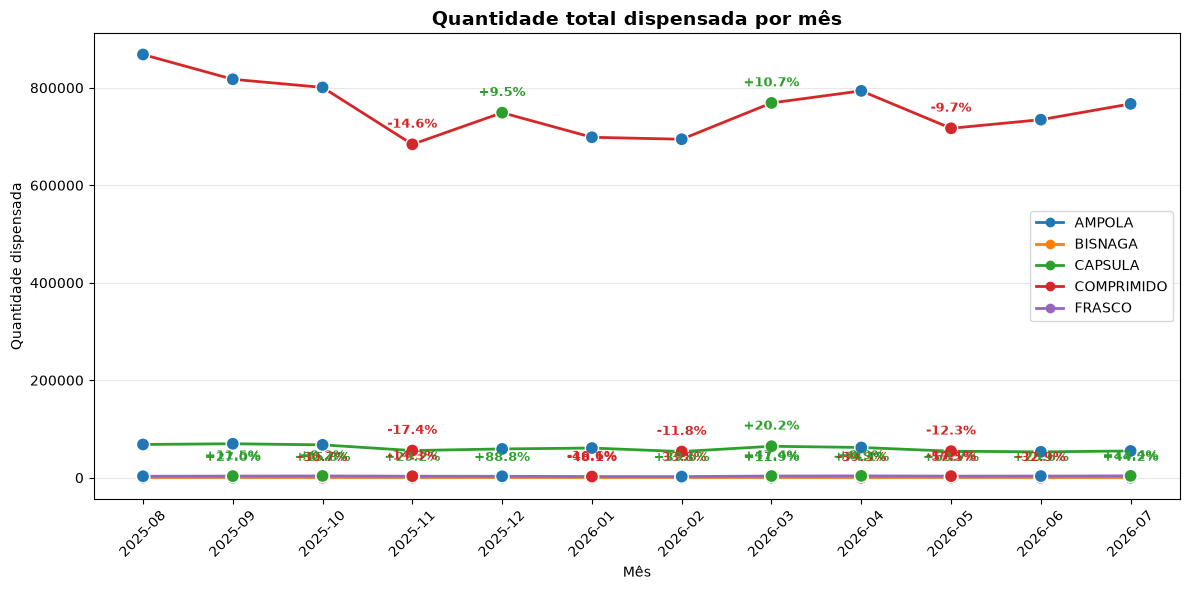

In [31]:
variacao_mensal_coluna(df, 'material_tipo')


Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-09        4675     25.167336
    2025-10        4285     -8.342246
    2025-11        1945    -54.609102
    2026-01        2465     19.951338
    2026-02        3285     33.265720
    2026-03        3575      8.828006
    2026-05        3005    -13.275613
    2026-07        2669    -10.735786

Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-11       32745    -12.656708
    2026-03       34946      8.125000
    2026-04       52705     50.818406
    2026-05       27120    -48.543781
    2026-06       43899     61.869469
    2026-07       23573    -46.301738

Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-09        2583     31.250000
    2025-10        2197    -14.943864
    2025-11        1728    -21.347292
    2025-12        2589     49.826389
    2026-01        2219    -14.291232
    2026-02        1940    -12.573231


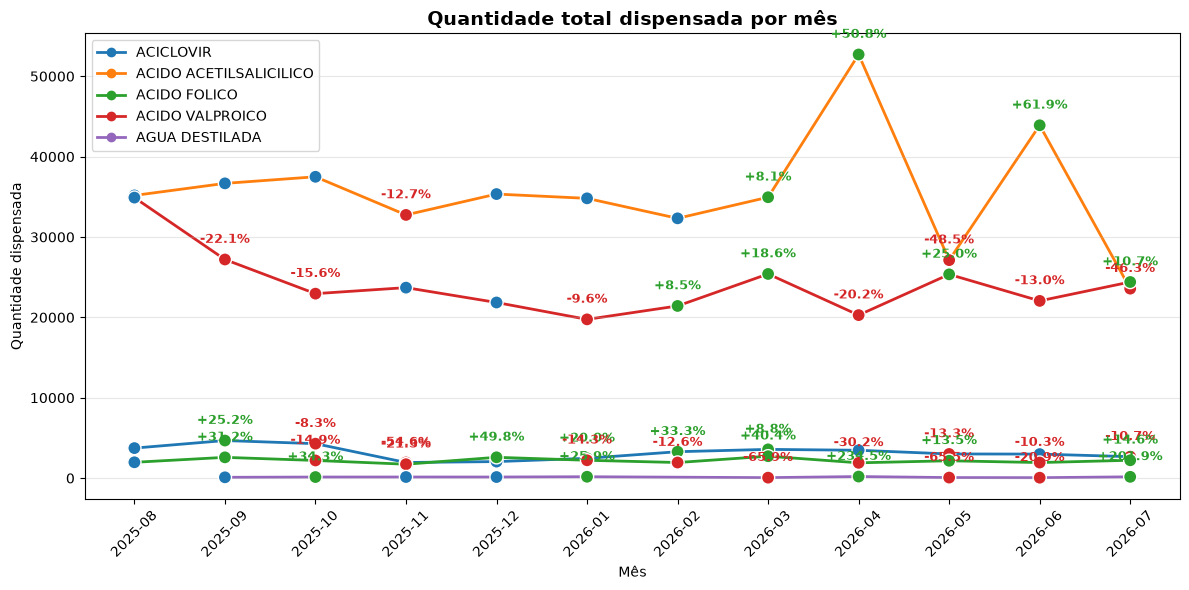

In [32]:
variacao_mensal_coluna(df, 'material_nome_base')


Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-09        2615     26.084860
    2025-10        1389    -46.883365
    2025-11        1864     34.197264
    2025-12        2098     12.553648
    2026-01        1595    -23.975214
    2026-02        1172    -26.520376
    2026-03        1811     54.522184
    2026-04        2628     45.113197
    2026-05        1379    -47.526636
    2026-07        2690     98.817443

Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-09       19650    -19.055858
    2025-10       23213     18.132316
    2025-11       16178    -30.306294
    2025-12       20544     26.987267
    2026-01       18293    -10.956970
    2026-02       19987      9.260373
    2026-06       21168     11.433986
    2026-07       18606    -12.103175

Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-11          30    -25.000000
    2026-02          51     70.000000


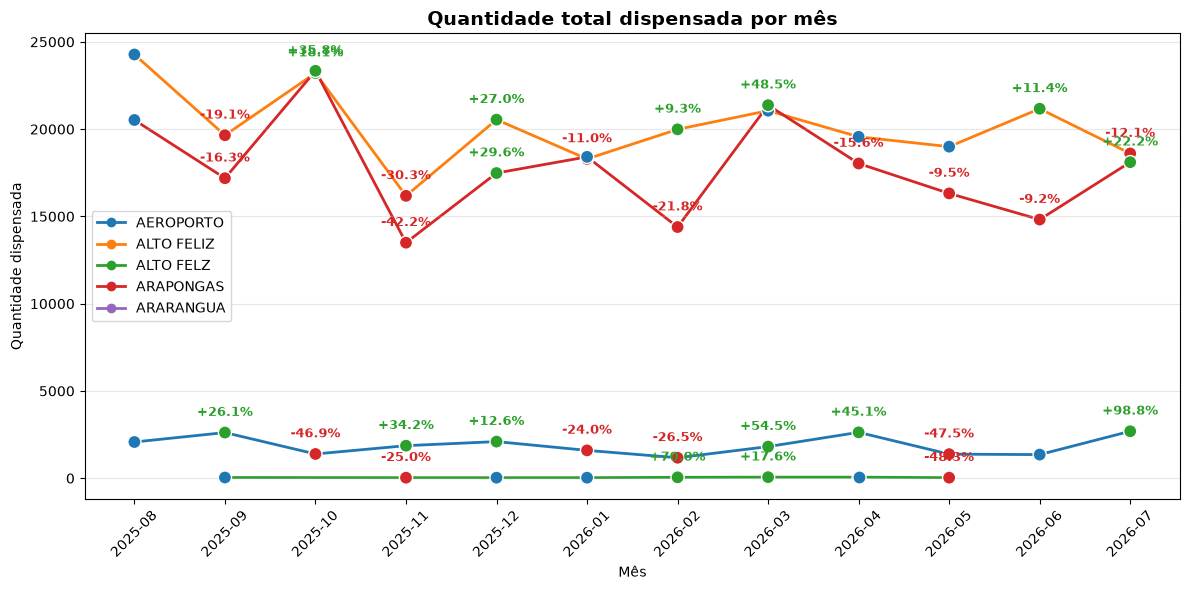

In [33]:
variacao_mensal_coluna(df, 'bairro_nome')


Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-09       25043    -12.605130
    2025-10       21744    -13.173342
    2025-11       14230    -34.556659
    2025-12       17270     21.363317
    2026-01       26611     54.088014
    2026-02       23127    -13.092330
    2026-03       25237      9.123535
    2026-05       31829     20.359236
    2026-06       24008    -24.571931
    2026-07       34468     43.568810

Períodos com variação relevante (>= 8%):
ano_mes_str  quantidade  variacao_pct
    2025-09        6898     -8.234668
    2025-10        6205    -10.046390
    2025-11        6860     10.556003
    2025-12        6121    -10.772595
    2026-01        3491    -42.966835
    2026-02        7972    128.358636
    2026-03        3804    -52.282990
    2026-04        6546     72.082019
    2026-05        4329    -33.868011
    2026-06        6623     52.991453
    2026-07        4015    -39.377925

Períodos com variação relevante (>= 8%):


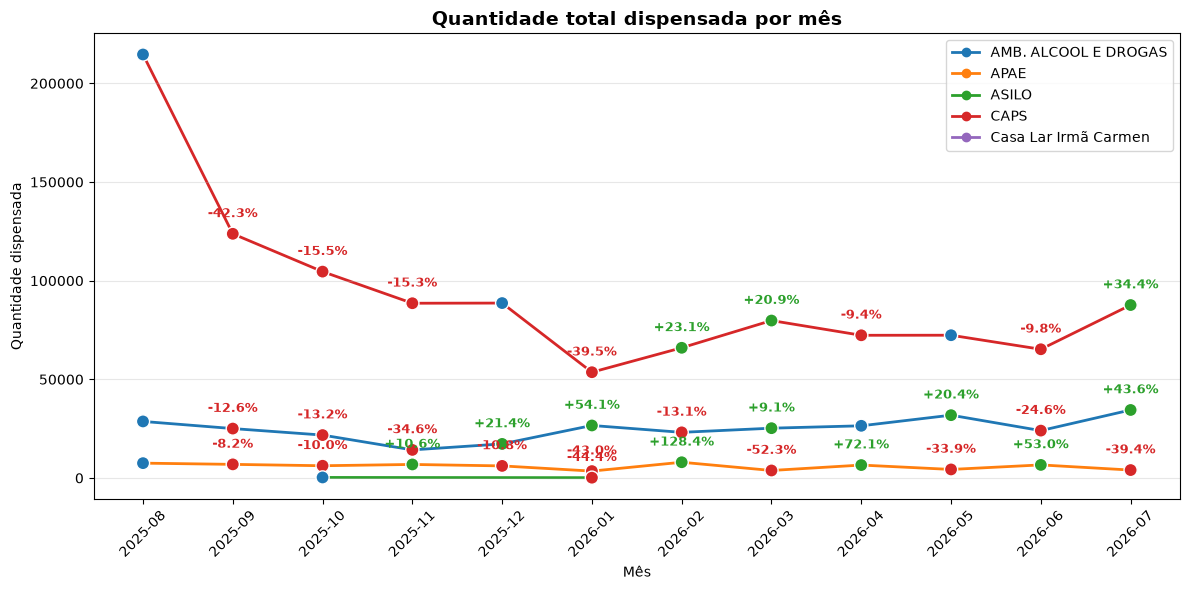

In [34]:
variacao_mensal_coluna(df, 'centro_custo_nome')

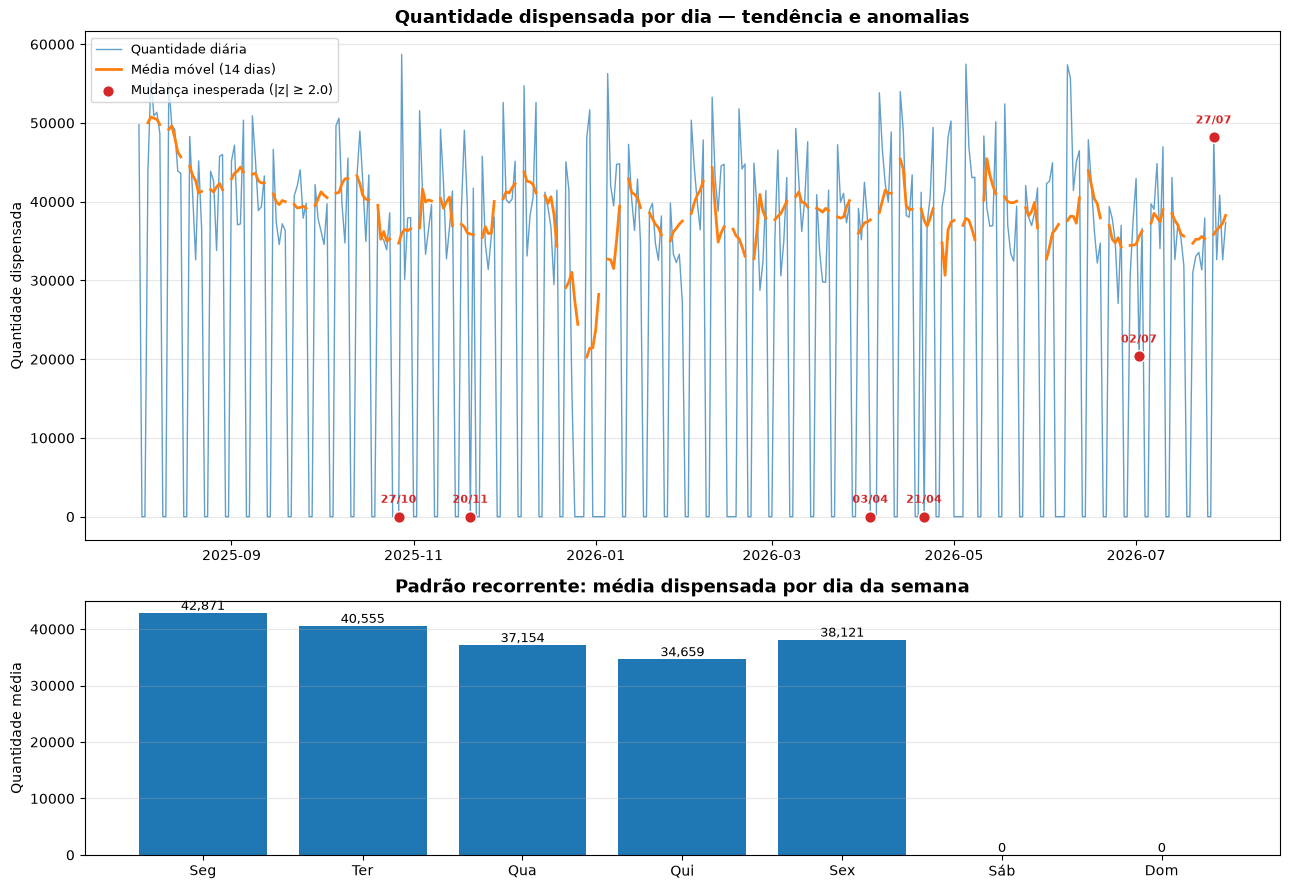

=== PADRÃO RECORRENTE (dia da semana) ===
dia_semana
Seg    42871.4
Ter    40555.3
Qua    37154.1
Qui    34659.0
Sex    38120.9
Sáb        0.0
Dom        0.0

-> Dispensação é sistematicamente menor em Sáb e maior em Seg.

=== MUDANÇAS INESPERADAS (|z-score| >= 2.0) ===
      data  quantidade  media_movel  z_score
27/10/2025         0.0      34738.7     -2.4
20/11/2025         0.0      35902.6     -2.6
03/04/2026         0.0      37698.7     -2.6
21/04/2026         0.0      37643.8     -2.7
02/07/2026     20354.0      35579.2     -2.0
27/07/2026     48184.0      35856.2      2.3


In [35]:
diario = df.groupby('data')['quantidade'].sum().asfreq('D').fillna(0).reset_index()
diario.columns = ['data', 'quantidade']

# 3. Remover os últimos dias se o mês corrente estiver incompleto
ultimo_mes = diario['data'].max().to_period('M')
dias_ultimo_mes = (diario['data'].dt.to_period('M') == ultimo_mes).sum()
if dias_ultimo_mes < 15:
    diario = diario[diario['data'].dt.to_period('M') != ultimo_mes]

# 4. PADRÃO QUE SE REPETE: sazonalidade por dia da semana
diario['dia_semana'] = diario['data'].dt.dayofweek  # 0=Seg ... 6=Dom
nomes_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
padrao_semanal = diario.groupby('dia_semana')['quantidade'].mean().reindex(range(7))

# 5. MUDANÇAS INESPERADAS: z-score sobre média/desvio móvel (janela de 10 dias úteis)
#    calculado só com dias úteis, pois fins de semana têm dispensação zero
#    (farmácia fechada) e distorceriam o desvio-padrão local
diario = diario.sort_values('data').reset_index(drop=True)
uteis = diario[diario['dia_semana'] < 5].copy().reset_index(drop=True)
uteis['media_movel'] = uteis['quantidade'].rolling(10, min_periods=5, center=True).mean()
uteis['std_movel'] = uteis['quantidade'].rolling(10, min_periods=5, center=True).std()
uteis['z_score'] = (uteis['quantidade'] - uteis['media_movel']) / uteis['std_movel']

LIMIAR_Z = 2.0  # "mudança inesperada" = desvio >= 2 desvios-padrão da média móvel local
uteis['anomalia'] = uteis['z_score'].abs() >= LIMIAR_Z

diario = diario.merge(uteis[['data', 'media_movel', 'std_movel', 'z_score', 'anomalia']], on='data', how='left')
diario['anomalia'] = diario['anomalia'].fillna(False)

# 6. Plotar: painel superior = série diária com anomalias / painel inferior = padrão semanal
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={'height_ratios': [2, 1]})

ax1.plot(diario['data'], diario['quantidade'], color='#1f77b4', linewidth=1, alpha=0.7, label='Quantidade diária')
ax1.plot(diario['data'], diario['media_movel'], color='#ff7f0e', linewidth=2, label='Média móvel (14 dias)')

anomalias = diario[diario['anomalia']]
ax1.scatter(anomalias['data'], anomalias['quantidade'], color='#d62728', s=70, zorder=5,
            edgecolor='white', label=f'Mudança inesperada (|z| ≥ {LIMIAR_Z})')

for _, row in anomalias.iterrows():
    ax1.annotate(row['data'].strftime('%d/%m'), (row['data'], row['quantidade']),
                 textcoords="offset points", xytext=(0, 10), ha='center',
                 fontsize=8, fontweight='bold', color='#d62728')

ax1.set_title('Quantidade dispensada por dia — tendência e anomalias', fontsize=13, fontweight='bold')
ax1.set_ylabel('Quantidade dispensada')
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(axis='y', alpha=0.3)

cores_barra = ['#1f77b4' if d < 5 else '#9467bd' for d in range(7)]
ax2.bar(nomes_dias, padrao_semanal.values, color=cores_barra)
ax2.set_title('Padrão recorrente: média dispensada por dia da semana', fontsize=13, fontweight='bold')
ax2.set_ylabel('Quantidade média')
ax2.grid(axis='y', alpha=0.3)
for i, v in enumerate(padrao_semanal.values):
    ax2.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('grafico_padroes_e_anomalias.png', dpi=150)
plt.show()

# 7. Resumir achados em texto
print("=== PADRÃO RECORRENTE (dia da semana) ===")
print(padrao_semanal.round(1).rename(index=dict(enumerate(nomes_dias))).to_string())
print(f"\n-> Dispensação é sistematicamente menor em {nomes_dias[padrao_semanal.idxmin()]} "
      f"e maior em {nomes_dias[padrao_semanal.idxmax()]}.")

print(f"\n=== MUDANÇAS INESPERADAS (|z-score| >= {LIMIAR_Z}) ===")
if len(anomalias):
    tabela = anomalias[['data', 'quantidade', 'media_movel', 'z_score']].copy()
    tabela['data'] = tabela['data'].dt.strftime('%d/%m/%Y')
    tabela[['quantidade', 'media_movel', 'z_score']] = tabela[['quantidade', 'media_movel', 'z_score']].round(1)
    print(tabela.to_string(index=False))
else:
    print("Nenhum dia fora do padrão esperado foi encontrado.")

# **Desvio padrão (z_score):**

**Cálculo: Desvio padrão = (quantidade do dia - média móvel local) / desvio-padrão local**


**indícios:**

z = 0 → o dia foi exatamente igual à média dos dias ao redor (comportamento normal).

z = +2 → o dia teve dispensação 2 desvios-padrão acima da média local (bem mais alto que o normal).

z = -2 → o dia teve dispensação 2 desvios-padrão abaixo da média local (bem mais baixo que o normal).

Exemplo do seu dado: 27/07/2026 teve quantidade = 48.184, enquanto a média local era ~35.900 e o desvio-padrão local dava um z de +2.3 — ou seja, esse dia se destacou de forma estatisticamente incomum em relação aos dias ao redor dele, não só "pareceu alto".